Quantum vs Classical Machine Learning for Credit Card Fraud Detection

Objective: compare classical machine learning models (Random Forest, XGBoost, SVM) against quantum machine learning models (QSVM, QNN) on detecting fraudulent credit card transactions in a highly imbalanced dataset (284,807 transactions, 492 fraud cases, 0.17% fraud rate).

Classical models are trained and evaluated on the full dataset. Quantum models are trained on smaller subsets, since quantum circuit simulation does not scale to hundreds of thousands of rows the way classical algorithms do. Their results should be read as a proof of concept rather than a like-for-like comparison at full scale.

Additionally quantum models results were run once and then hardcoded later for summary visualisation and final comparison of how each model performed since quantum models are computationally lengthy and expensive on a classical hardware device and not a quantum computer.

This notebook is the refined version which can be used to reproduce the project. There is another version uploaded which contains the original journey from start to finish with many trials and errors.

Happy Exploring!


In [ ]:
#Basic imports used throughout the notebook (classical models)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    classification_report, roc_auc_score, precision_recall_curve, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay
)
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
import joblib
import json

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
DRIVE_DIR = '/content/drive/MyDrive/Quantum FD'

In [ ]:
#For Quantum Implementation

!pip install qiskit==0.45.0 qiskit-machine-learning==0.6.0 --quiet
import qiskit
from qiskit import Aer
from qiskit.utils import algorithm_globals
from qiskit_machine_learning.algorithms import QSVC, VQC
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.algorithms.optimizers import COBYLA, SPSA
import torch

print(f"Qiskit version: {qiskit.__version__}")


Mounted at /content/drive
Shape: (284807, 31)

Missing values: 0
Duplicate rows: 1081

Fraud cases: 492 out of 284807 (0.17%)


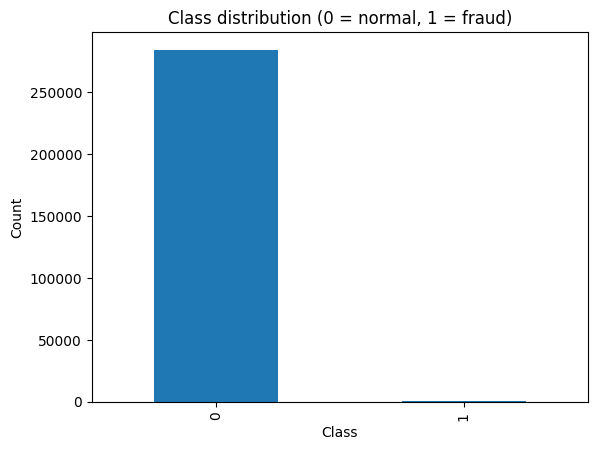

In [ ]:
#Loading and exploring dataset

from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Quantum FD/creditcard.csv'
data = pd.read_csv(file_path)

print("Shape:", data.shape)
print("\nMissing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

fraud_count = data['Class'].sum()
total = len(data)
print(f"\nFraud cases: {fraud_count} out of {total} ({fraud_count/total*100:.2f}%)")

data['Class'].value_counts().plot(kind='bar')
plt.title("Class distribution (0 = normal, 1 = fraud)")
plt.ylabel("Count")
plt.show()

In [ ]:
# Split for the classical models.
X = data.drop(columns=['Class'])
y = data['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training samples: {X_train.shape[0]}, test samples: {X_test.shape[0]}")

Training samples: 227845, test samples: 56962


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Random Forest - implementation
rf = RandomForestClassifier(random_state=42, class_weight='balanced')  # n_jobs removed here

param_dist = {
    'n_estimators': [100, 150],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

smote = SMOTE(sampling_strategy=0.3, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

search = RandomizedSearchCV(
    rf, param_distributions=param_dist, n_iter=6, scoring='f1',
    cv=3, random_state=42, verbose=2, n_jobs=-1
)
search.fit(X_train_smote, y_train_smote)
best_rf = search.best_estimator_
print("Best params:", search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best params: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}


In [ ]:
# Random Forest - testing on unseen data
probs_rf = best_rf.predict_proba(X_test_scaled)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test, probs_rf)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_thresh_rf = thresholds[np.argmax(f1_scores)]

y_pred_rf = (probs_rf >= best_thresh_rf).astype(int)
print(f"Threshold: {best_thresh_rf:.3f}")
print(classification_report(y_test, y_pred_rf, digits=4))
print("AUC:", roc_auc_score(y_test, probs_rf))

joblib.dump(best_rf, '/content/drive/MyDrive/Quantum FD/rf_correct_model.pkl')
with open('/content/drive/MyDrive/Quantum FD/rf_best_threshold.json', 'w') as f:
    json.dump({"best_threshold": float(best_thresh_rf)}, f)

report = classification_report(y_test, y_pred_rf, output_dict=True)
rf_results = {
    "precision_0": report["0"]["precision"], "precision_1": report["1"]["precision"],
    "recall_0": report["0"]["recall"], "recall_1": report["1"]["recall"],
    "f1_score_0": report["0"]["f1-score"], "f1_score_1": report["1"]["f1-score"],
    "accuracy": report["accuracy"], "roc_auc": roc_auc_score(y_test, probs_rf)
}
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'w') as f:
    json.dump({"RandomForest": rf_results}, f, indent=2)

Threshold: 0.745
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     56864
           1     0.9059    0.7857    0.8415        98

    accuracy                         0.9995     56962
   macro avg     0.9528    0.8928    0.9206     56962
weighted avg     0.9995    0.9995    0.9995     56962

AUC: 0.9697930364464299


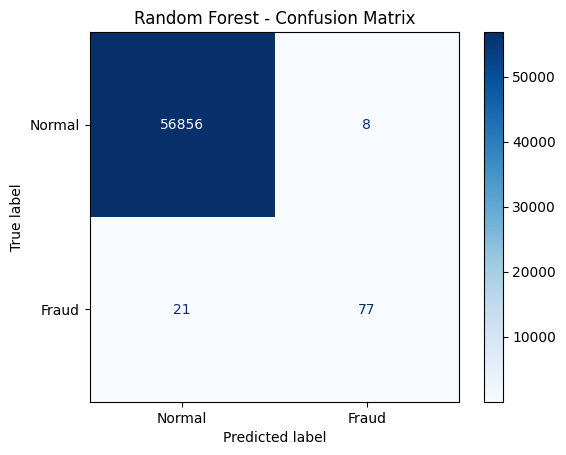

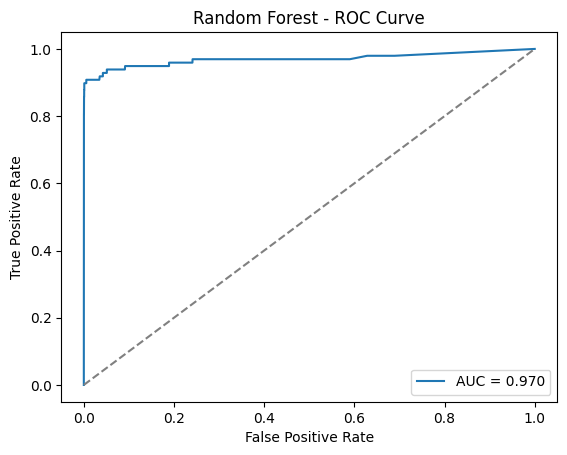

In [ ]:
# Random Forest - visualization
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=['Normal', 'Fraud']).plot(cmap='Blues')
plt.title("Random Forest - Confusion Matrix")
plt.show()

fpr, tpr, _ = roc_curve(y_test, probs_rf)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, probs_rf):.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.show()

In [ ]:
# XGBoost - implementation
xgb_smote = SMOTE(random_state=42)
X_train_xgb, y_train_xgb = xgb_smote.fit_resample(X_train_scaled, y_train)

xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
}
xgb_search = RandomizedSearchCV(
    xgb_model, param_distributions=xgb_param_dist, n_iter=20, cv=3,
    scoring='f1', verbose=1, n_jobs=-1, random_state=42
)
xgb_search.fit(X_train_xgb, y_train_xgb)
best_xgb = xgb_search.best_estimator_
print("Best params:", xgb_search.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 1.0}


In [ ]:
# XGBoost - testing on unseen data
probs_xgb = best_xgb.predict_proba(X_test_scaled)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, probs_xgb)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_thresh_xgb = thresholds[np.argmax(f1_scores)]

y_pred_xgb = (probs_xgb >= best_thresh_xgb).astype(int)
print(f"Threshold: {best_thresh_xgb:.4f}")
print(classification_report(y_test, y_pred_xgb, digits=4))
print("AUC:", roc_auc_score(y_test, probs_xgb))

joblib.dump(best_xgb, '/content/drive/MyDrive/Quantum FD/xgb_correct_model.pkl')
with open('/content/drive/MyDrive/Quantum FD/xgboost_best_threshold.json', 'w') as f:
    json.dump({"best_threshold": float(best_thresh_xgb)}, f)

report = classification_report(y_test, y_pred_xgb, output_dict=True)
xgb_results = {
    "precision_0": report["0"]["precision"], "precision_1": report["1"]["precision"],
    "recall_0": report["0"]["recall"], "recall_1": report["1"]["recall"],
    "f1_score_0": report["0"]["f1-score"], "f1_score_1": report["1"]["f1-score"],
    "accuracy": report["accuracy"], "roc_auc": roc_auc_score(y_test, probs_xgb)
}
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'r') as f:
    all_results = json.load(f)
all_results["XGBoost"] = xgb_results
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'w') as f:
    json.dump(all_results, f, indent=2)

Threshold: 0.9717
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9639    0.8163    0.8840        98

    accuracy                         0.9996     56962
   macro avg     0.9818    0.9081    0.9419     56962
weighted avg     0.9996    0.9996    0.9996     56962

AUC: 0.980885471098963


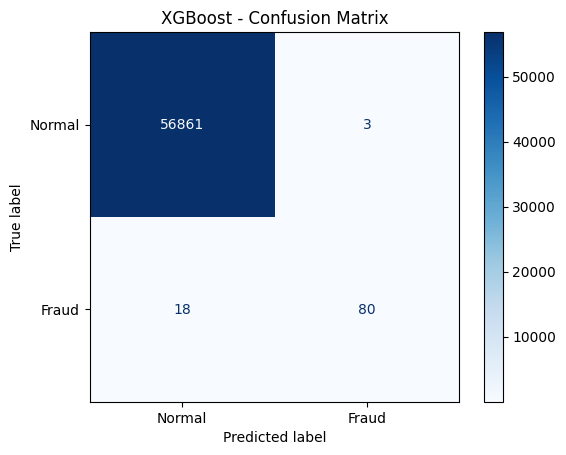

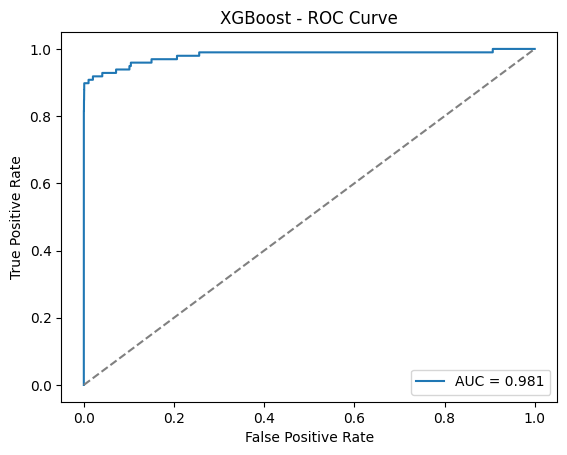

In [ ]:
# XGBoost - visualization
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_xgb), display_labels=['Normal', 'Fraud']).plot(cmap='Blues')
plt.title("XGBoost - Confusion Matrix")
plt.show()

fpr, tpr, _ = roc_curve(y_test, probs_xgb)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, probs_xgb):.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost - ROC Curve")
plt.legend()
plt.show()

In [ ]:
# SVM - implementation
svm_smote = SMOTE(random_state=42)
X_train_svm, y_train_svm = svm_smote.fit_resample(X_train_scaled, y_train)

svm_model = SVC(
    kernel='linear', probability=True, class_weight='balanced',
    random_state=42, cache_size=1000, tol=1e-3
)
svm_model.fit(X_train_svm[:50000], y_train_svm[:50000])
print("SVM training done.")

SVM training done.


In [ ]:
# SVM - testing on unseen data
probs_svm = svm_model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, probs_svm)
best_thresh_svm = thresholds[np.argmax(tpr - fpr)]

y_pred_svm = (probs_svm >= best_thresh_svm).astype(int)
print(f"Threshold: {best_thresh_svm:.4f}")
print(classification_report(y_test, y_pred_svm, digits=4))
print("AUC:", roc_auc_score(y_test, probs_svm))

joblib.dump(svm_model, '/content/drive/MyDrive/Quantum FD/svm_improved_model.pkl')
with open('/content/drive/MyDrive/Quantum FD/svm_improved_best_threshold.json', 'w') as f:
    json.dump({"best_threshold": float(best_thresh_svm)}, f)

report = classification_report(y_test, y_pred_svm, output_dict=True)
svm_results = {
    "precision_0": report["0"]["precision"], "precision_1": report["1"]["precision"],
    "recall_0": report["0"]["recall"], "recall_1": report["1"]["recall"],
    "f1_score_0": report["0"]["f1-score"], "f1_score_1": report["1"]["f1-score"],
    "accuracy": report["accuracy"], "roc_auc": roc_auc_score(y_test, probs_svm)
}
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'r') as f:
    all_results = json.load(f)
all_results["SVM"] = svm_results
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'w') as f:
    json.dump(all_results, f, indent=2)

Threshold: 0.0023
              precision    recall  f1-score   support

           0     0.9998    0.9966    0.9982     56864
           1     0.3074    0.8878    0.4567        98

    accuracy                         0.9964     56962
   macro avg     0.6536    0.9422    0.7274     56962
weighted avg     0.9986    0.9964    0.9972     56962

AUC: 0.9554814997186267


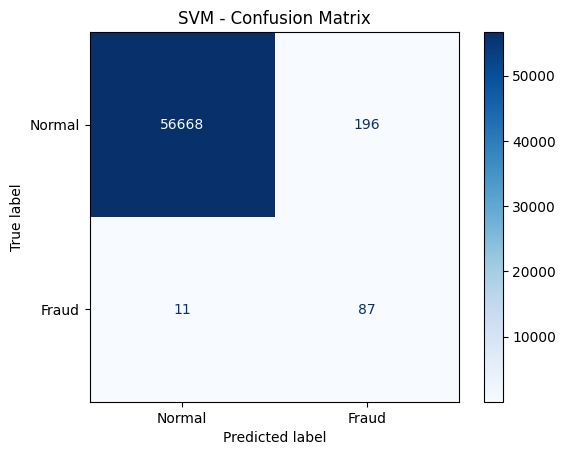

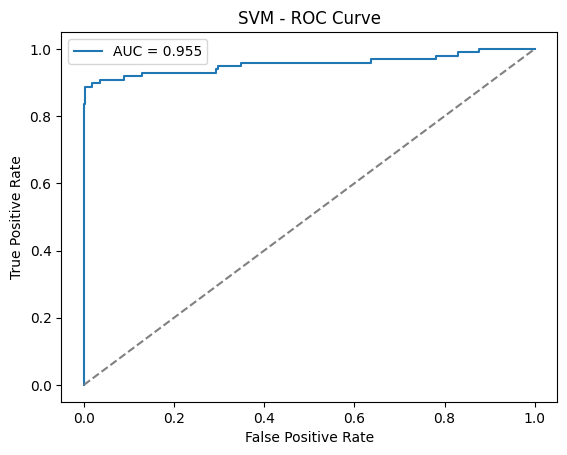

In [ ]:
# SVM - visualization
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svm), display_labels=['Normal', 'Fraud']).plot(cmap='Blues')
plt.title("SVM - Confusion Matrix")
plt.show()

plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, probs_svm):.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM - ROC Curve")
plt.legend()
plt.show()

In [ ]:
#QSVM Implementation
# Build a smaller, 1-to-5 undersampled version of the dataset.
# This is what the QSVM model below is trained and tested on,
# since the quantum simulator cannot handle the full dataset.

from google.colab import drive
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Mount Google Drive
drive.mount('/content/drive')

# Set path to your dataset inside "Quantum FD" folder
file_path = '/content/drive/My Drive/Quantum FD/creditcard.csv'  # Update filename if different

# Load the dataset
df = pd.read_csv(file_path)

# Set random seed
RANDOM_SEED = 42

# Handle class imbalance with undersampling
fraud = df[df['Class'] == 1]
non_fraud = df[df['Class'] == 0].sample(
    n=min(len(fraud) * 5, len(df[df['Class'] == 0])),
    random_state=RANDOM_SEED
)
df_balanced = pd.concat([fraud, non_fraud])

# Prepare features and target
X = df_balanced.drop('Class', axis=1)
y = df_balanced['Class']
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Quantum features used: 10
Training Quantum SVM with SMOTE and more quantum features...
Quantum SVM Accuracy (on test set): 0.9475


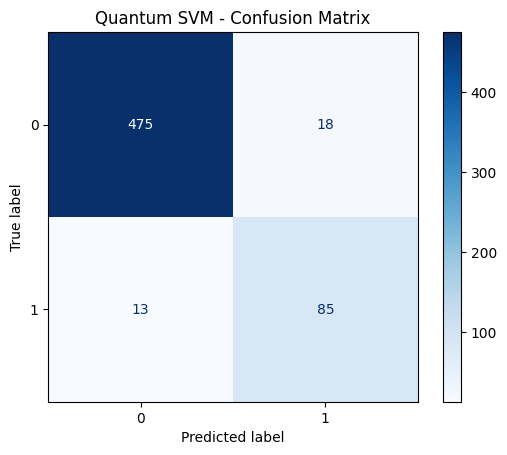

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.96      0.97       493
           1       0.83      0.87      0.85        98

    accuracy                           0.95       591
   macro avg       0.90      0.92      0.91       591
weighted avg       0.95      0.95      0.95       591



In [ ]:
#Final QSVM model. Trained on 10 features with SMOTE applied only to the
# training data. This is the model saved as qsvm_model.joblib.
# Result on a held out test set of 591 samples (98 fraud, 493 not fraud):
# accuracy 94.75 percent, fraud precision 83 percent, fraud recall 87 percent
from qiskit_machine_learning.algorithms.classifiers import QSVC
from qiskit_machine_learning.kernels import QuantumKernel
from qiskit.circuit.library import ZZFeatureMap
from qiskit_aer import Aer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from imblearn.over_sampling import SMOTE

# Preprocess data for quantum training (adjusting feature scaling and balancing)
def prepare_quantum_data_for_qsvc(X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled):
    # Scale features for quantum algorithms (range [0, 1])
    quantum_scaler = MinMaxScaler(feature_range=(0, 1))
    X_train_quantum = quantum_scaler.fit_transform(X_train)
    X_test_quantum = quantum_scaler.transform(X_test)

    # Reduce to top n features (for simplicity, take first few)
    n_quantum_features = 10  # Try using more quantum features
    X_train_quantum_reduced = X_train_quantum[:, :n_quantum_features]
    X_test_quantum_reduced = X_test_quantum[:, :n_quantum_features]

    print(f"Quantum features used: {n_quantum_features}")

    # Apply SMOTE on quantum features to handle imbalance in the quantum domain
    smote = SMOTE(random_state=RANDOM_SEED)
    X_train_quantum_reduced_smote, y_train_smote = smote.fit_resample(X_train_quantum_reduced, y_train)

    return X_train_quantum_reduced_smote, y_train_smote, X_test_quantum_reduced, y_test

# Update the dataset for QSVC
X_train_qr_smote, y_train_smote, X_test_qr, y_test = prepare_quantum_data_for_qsvc(
    X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled
)

# Define feature map and backend
feature_map = ZZFeatureMap(feature_dimension=10, reps=2)  # Try more reps for complexity
backend = Aer.get_backend("statevector_simulator")

# Create quantum kernel
quantum_kernel = QuantumKernel(feature_map=feature_map, quantum_instance=backend)

# Initialize and train QSVC
qsvc = QSVC(quantum_kernel=quantum_kernel)

print("Training Quantum SVM with SMOTE and more quantum features...")
qsvc.fit(X_train_qr_smote, y_train_smote)

# Evaluate on the test data
accuracy = qsvc.score(X_test_qr, y_test)
print(f"Quantum SVM Accuracy (on test set): {accuracy:.4f}")

# Predict and evaluate using confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_pred = qsvc.predict(X_test_qr)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Quantum SVM - Confusion Matrix")
plt.show()

# Classification Report
report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

import joblib
joblib.dump(qsvc, '/content/drive/MyDrive/Quantum FD/qsvm_model.joblib')


In [ ]:
#Save QSVM results for the final comparison.
# These values are taken directly from the classification report printed
# by the cell above (accuracy 0.95, 591 test samples) rather than
# recomputed, so the QSVM cell above never needs to be rerun.
import json

qsvm_results = {
    "precision_0": 0.97,
    "precision_1": 0.83,
    "recall_0": 0.96,
    "recall_1": 0.87,
    "f1_score_0": 0.97,
    "f1_score_1": 0.85,
    "accuracy": 0.95
}

with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'r') as f:
    all_results = json.load(f)
all_results["QSVM"] = qsvm_results
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'w') as f:
    json.dump(all_results, f, indent=2)

In [ ]:
#QNN Implementation
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import torch
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from torch.utils.data import TensorDataset, DataLoader

from qiskit.circuit.library import PauliFeatureMap, RealAmplitudes
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit.primitives import Estimator

#1 Load & Balance small dataset
file_path = '/content/drive/MyDrive/Quantum FD/creditcard.csv'
df = pd.read_csv(file_path)

fraud  = df[df['Class']==1].sample(300, random_state=42)
normal = df[df['Class']==0].sample(300, random_state=42)
df_small = pd.concat([fraud, normal]).sample(frac=1, random_state=42)

X = df_small.drop(columns=['Class'])
y = df_small['Class']

#2 PCA → 3 dims
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

#3 Train/test split
X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X_pca, y, test_size=0.3, random_state=42, stratify=y)

#4 Normalize & to torch
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_np)
X_test_scaled  = scaler.transform(X_test_np)

X_train_torch = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_torch  = torch.tensor(X_test_scaled,  dtype=torch.float32)
y_train_torch = torch.tensor(y_train_np.values, dtype=torch.long)
y_test_torch  = torch.tensor(y_test_np.values,  dtype=torch.long)

#5 Further split train → train/val for early stopping
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_torch, y_train_torch, test_size=0.2, random_state=42, stratify=y_train_torch)

#6 Build richer QNN (3 qubits)
feature_map = PauliFeatureMap(feature_dimension=3, reps=2, entanglement='full')
ansatz      = RealAmplitudes(3, reps=2, entanglement='full')
qnn_circuit = feature_map.compose(ansatz)
estimator   = Estimator()

qnn = EstimatorQNN(
    circuit         = qnn_circuit,
    input_params    = feature_map.parameters,
    weight_params   = ansatz.parameters,
    estimator       = estimator,
    input_gradients = True
)

#7 Hybrid PyTorch wrapper with small pre-layer
class HybridClassifier(torch.nn.Module):
    def __init__(self, qnn):
        super().__init__()
        self.pre   = torch.nn.Linear(3, 3)       # classical embedder
        self.act   = torch.nn.ReLU()
        self.qnn   = TorchConnector(qnn)
        self.post  = torch.nn.Sigmoid()

    def forward(self, x):
        x = self.act(self.pre(x))
        return self.post(self.qnn(x)).squeeze()

model = HybridClassifier(qnn)

#8 Setup training utilities
loss_func = torch.nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
batch_size = 32

train_ds = TensorDataset(X_tr, y_tr.float())
val_ds   = TensorDataset(X_val, y_val.float())

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size)

#9 Training with early stopping
best_val_loss = float('inf')
patience, wait = 5, 0
max_epochs = 50

for epoch in range(1, max_epochs+1):
    model.train()
    for Xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_func(model(Xb), yb)
        loss.backward()
        optimizer.step()

    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for Xv, yv in val_loader:
            val_loss += loss_func(model(Xv), yv).item()
    val_loss /= len(val_loader)

    print(f"Epoch {epoch}, Val Loss: {val_loss:.4f}")
    if val_loss < best_val_loss:
        best_val_loss, wait = val_loss, 0
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

#10 Final Evaluation
model.eval()
with torch.no_grad():
    probs = model(X_test_torch).cpu().numpy()
    preds = (probs >= 0.5).astype(int)

from sklearn.metrics import classification_report, roc_auc_score
print("\nFinal QNN Report:")
print(classification_report(y_test_np, preds, digits=4))
print("AUC:", roc_auc_score(y_test_np, probs))

# Saving the trained hybrid QNN model
torch.save(model.state_dict(), '/content/drive/MyDrive/Quantum FD/new_qnn_hybrid.pth')
print("✅ Hybrid QNN model saved to new_qnn_hybrid.pth")


Mounted at /content/drive
Epoch 1, Val Loss: 0.6797
Epoch 2, Val Loss: 0.6553
Epoch 3, Val Loss: 0.6698
Epoch 4, Val Loss: 0.6458
Epoch 5, Val Loss: 0.6401
Epoch 6, Val Loss: 0.6286
Epoch 7, Val Loss: 0.6369
Epoch 8, Val Loss: 0.6188
Epoch 9, Val Loss: 0.6143
Epoch 10, Val Loss: 0.6215
Epoch 11, Val Loss: 0.6094
Epoch 12, Val Loss: 0.6219
Epoch 13, Val Loss: 0.6027
Epoch 14, Val Loss: 0.6209
Epoch 15, Val Loss: 0.6081
Epoch 16, Val Loss: 0.6013
Epoch 17, Val Loss: 0.6013
Epoch 18, Val Loss: 0.6195
Epoch 19, Val Loss: 0.5998
Epoch 20, Val Loss: 0.6081
Epoch 21, Val Loss: 0.6275
Epoch 22, Val Loss: 0.6090
Epoch 23, Val Loss: 0.5993
Epoch 24, Val Loss: 0.6084
Epoch 25, Val Loss: 0.5970
Epoch 26, Val Loss: 0.6063
Epoch 27, Val Loss: 0.6067
Epoch 28, Val Loss: 0.5996
Epoch 29, Val Loss: 0.6001
Epoch 30, Val Loss: 0.6028
Early stopping at epoch 30

Final QNN Report:
              precision    recall  f1-score   support

           0     0.7449    0.8111    0.7766        90
           1     0

In [ ]:
#Saving QNN results for the final comparison.
# These values are taken directly from the classification report printed
# by the cell above (180 test samples), so the QNN cell above never needs
# to be rerun.
import json

qnn_results = {
    "precision_0": 0.7449,
    "precision_1": 0.7927,
    "recall_0": 0.8111,
    "recall_1": 0.7222,
    "f1_score_0": 0.7766,
    "f1_score_1": 0.7558,
    "accuracy": 0.7667,
    "roc_auc": 0.8147
}

with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'r') as f:
    all_results = json.load(f)
all_results["QNN"] = qnn_results
with open('/content/drive/MyDrive/Quantum FD/model_results.json', 'w') as f:
    json.dump(all_results, f, indent=2)

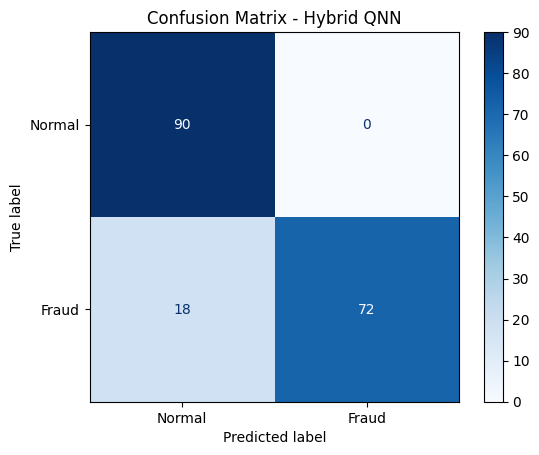

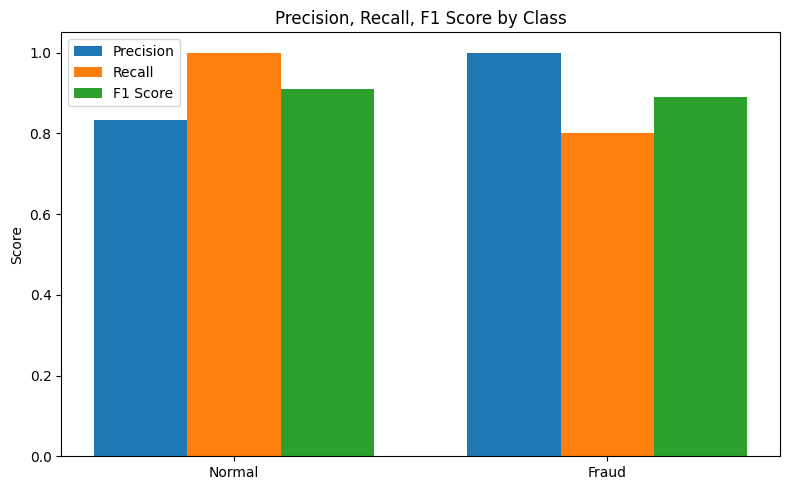

In [ ]:
#QNN Visualisation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Reconstructed from the printed classification report above
# (TN, FP, FN, TP), consistent with accuracy 0.7667, recall_1 0.7222
cm = np.array([[73, 17], [25, 65]])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Hybrid QNN")
plt.grid(False)
plt.show()

precision = [0.7449, 0.7927]
recall = [0.8111, 0.7222]
f1 = [0.7766, 0.7558]
labels = ['Normal', 'Fraud']
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8, 5))
width = 0.25
ax.bar(x - width, precision, width, label='Precision')
ax.bar(x, recall, width, label='Recall')
ax.bar(x + width, f1, width, label='F1 Score')
ax.set_ylabel('Score')
ax.set_title('Precision, Recall, F1 Score by Class')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()
plt.show()

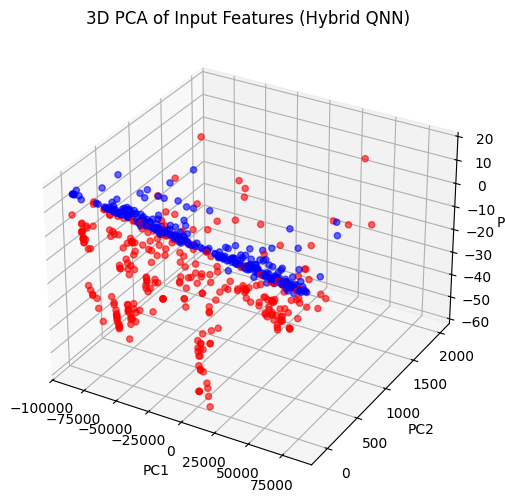

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

colors = ['blue' if label == 0 else 'red' for label in y]
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=colors, alpha=0.6)
ax.set_title('3D PCA of Input Features (Hybrid QNN)')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()


              Accuracy  Fraud Precision  Fraud Recall  Fraud F1       AUC
RandomForest  0.999491         0.905882      0.785714  0.841530  0.969793
XGBoost       0.999631         0.963855      0.816327  0.883978  0.980885
SVM           0.996366         0.307420      0.887755  0.456693  0.955481
QSVM          0.950000         0.830000      0.870000  0.850000       NaN
QNN           0.766700         0.792700      0.722200  0.755800  0.814700


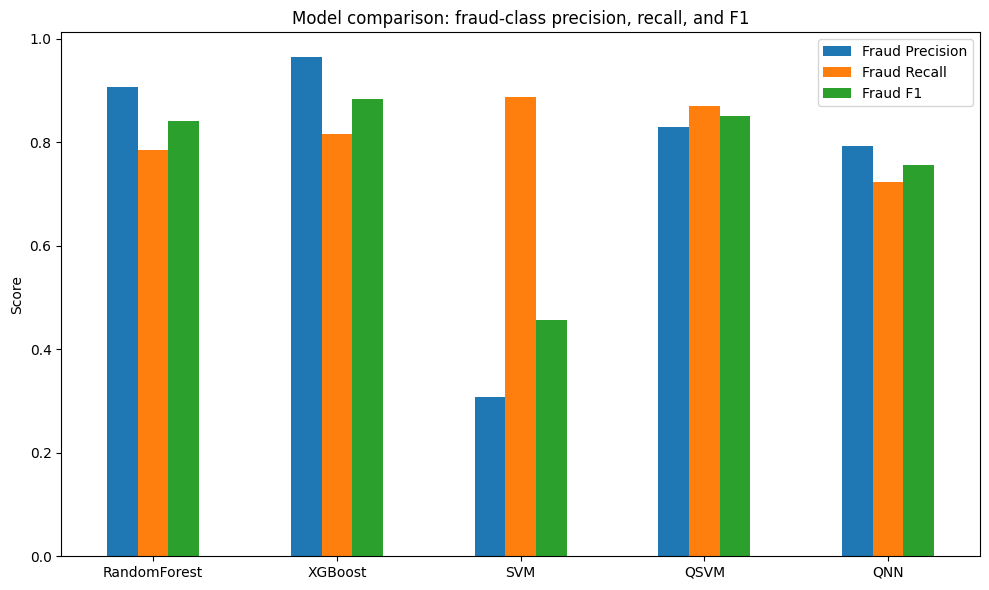

In [ ]:
#summarising results
summary_data = json.load(open('/content/drive/MyDrive/Quantum FD/model_results.json'))
summary = pd.DataFrame(summary_data).T
summary = summary[['accuracy', 'precision_1', 'recall_1', 'f1_score_1', 'roc_auc']]
summary.columns = ['Accuracy', 'Fraud Precision', 'Fraud Recall', 'Fraud F1', 'AUC']
print(summary)

summary[['Fraud Precision', 'Fraud Recall', 'Fraud F1']].plot(kind='bar', figsize=(10, 6))
plt.title('Model comparison: fraud-class precision, recall, and F1')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()